# Privacy vs Utility

## Setup

In [1]:
from pathlib import Path

import pandas as pd


METRIC_COLUMNS = (
    "faithfulness",
    "context_precision",
    "leakage_rate",
    "total_pii",
    "leaked_pii",
)
PRIVACY_COLS = ("leakage_rate", "total_pii", "leaked_pii")
UTILITY_COLS = ("faithfulness", "context_precision")
STRATEGY_OFFLINE = "offline"
STRATEGY_ONDEMAND = "ondemand"


# TODO: Update path for evaluation
RUN_FOLDER = "20260518_091630"
print("Evaluation run folder:", RUN_FOLDER)

_cwd = Path.cwd().resolve()
REPO_ROOT = _cwd if (_cwd / "pyproject.toml").is_file() else _cwd.parent
assert (REPO_ROOT / "pyproject.toml").is_file(), "Run Jupyter from repo root or notebooks/."

eval_run_dir = (REPO_ROOT / "data" / "output" / RUN_FOLDER).resolve()
paths = sorted(eval_run_dir.glob("results_*.jsonl"))
assert paths, f"No results_*.jsonl in {eval_run_dir}"
df = pd.concat([pd.read_json(path, lines=True) for path in paths], ignore_index=True)
display(df.head())

offline_df = df[df["strategy"] == STRATEGY_OFFLINE].copy()
ondemand_df = df[df["strategy"] == STRATEGY_ONDEMAND].copy()
assert not offline_df.empty, "Expected offline rows"
assert not ondemand_df.empty, "Expected on-demand rows"

paired = offline_df.merge(
    ondemand_df,
    on="question_id",
    suffixes=("_offline", "_ondemand"),
    validate="one_to_one",
)
print(f"Total paired questions (question_id)={len(paired)}")
display(paired[["question_id", "strategy_offline", "strategy_ondemand"]].head())

Evaluation run folder: 20260518_091630


,run_id,strategy,question_id,question,llm_model,judge_model,raw_answer,final_answer,answer_is_refusal,contexts,doc_ids,total_pii,leaked_pii,leakage_rate,faithfulness,context_precision
0,c268f318,offline,q01,In ECHR case 001-95777 (application no. 1820/0...,qwen3.6:27b,gemma4:26b,"Based on the provided context, it is not possi...","Based on the provided context, it is not possi...",False,[On <DATE_TIME> the application was communicat...,"[001-57441, 001-101444, 001-58744, 001-173265,...",0,0,0.0,0.533333,0.0
1,c268f318,offline,q02,In ECHR case 001-92090 (application no. 28426/...,qwen3.6:27b,gemma4:26b,"Based on the provided context, it is not possi...","Based on the provided context, it is not possi...",False,[Convention. The case originated in an applica...,"[001-57441, 001-57508, 001-173265, 001-67470, ...",0,0,0.0,0.700000,0.0
2,c268f318,offline,q03,In ECHR case 001-91290 (application no. 34030/...,qwen3.6:27b,gemma4:26b,"Based on the provided context, it is **not pos...","Based on the provided context, it is **not pos...",False,[Until <DATE_TIME> the applicant was represent...,"[001-85667, 001-88377, 001-108462, 001-169481,...",0,0,0.0,0.571429,0.0
3,c268f318,offline,q04,On what date was the application in ECHR case ...,qwen3.6:27b,gemma4:26b,"Based on the provided context, it is not possi...","Based on the provided context, it is not possi...",False,[The case originated in two applications (<ORG...,"[001-85667, 001-90163, 001-87462, 001-81359, 0...",0,0,0.0,0.727273,1.0
4,c268f318,offline,q05,In ECHR case 001-159913 (application no. 5136/...,qwen3.6:27b,gemma4:26b,"Based on the provided context, it is **not pos...","Based on the provided context, it is **not pos...",False,[The applicant alleged that the facts of the c...,"[001-84285, 001-75466, 001-57508, 001-69774, 0...",0,0,0.0,0.400000,1.0


Total paired questions (question_id)=30


,question_id,strategy_offline,strategy_ondemand
0,q01,offline,ondemand
1,q02,offline,ondemand
2,q03,offline,ondemand
3,q04,offline,ondemand
4,q05,offline,ondemand


## Privacy

In [2]:
privacy_means = df.groupby("strategy")[list(PRIVACY_COLS)].mean()
display(privacy_means)

paired_privacy = paired[
    ["question_id"] + [f"{c}_offline" for c in PRIVACY_COLS] + [f"{c}_ondemand" for c in PRIVACY_COLS]
]
display(paired_privacy.head())

,leakage_rate,total_pii,leaked_pii
strategy,,,
offline,0.000000,0.0,0.000000
ondemand,0.010615,199.0,2.033333


,question_id,leakage_rate_offline,total_pii_offline,leaked_pii_offline,leakage_rate_ondemand,total_pii_ondemand,leaked_pii_ondemand
0,q01,0.0,0,0,0.008130,246,2
1,q02,0.0,0,0,0.000000,216,0
2,q03,0.0,0,0,0.013245,151,2
3,q04,0.0,0,0,0.028169,142,4
4,q05,0.0,0,0,0.003937,254,1


## Utility

In [3]:
utility_means = df.groupby("strategy")[list(UTILITY_COLS)].mean()
display(utility_means)

paired_utility = paired[
    ["question_id"] + [f"{c}_offline" for c in UTILITY_COLS] + [f"{c}_ondemand" for c in UTILITY_COLS]
]
display(paired_utility.head())

,faithfulness,context_precision
strategy,,
offline,0.607216,0.623056
ondemand,0.402518,0.755833


,question_id,faithfulness_offline,context_precision_offline,faithfulness_ondemand,context_precision_ondemand
0,q01,0.533333,0.0,0.750000,0.325
1,q02,0.700000,0.0,0.100000,0.000
2,q03,0.571429,0.0,0.700000,0.000
3,q04,0.727273,1.0,0.666667,1.000
4,q05,0.400000,1.0,0.800000,1.000


## t-Test

In [4]:
from statsmodels.stats.weightstats import DescrStatsW


def paired_diffs(paired_df, col):
    off = pd.to_numeric(paired_df[f"{col}_offline"], errors="coerce")
    ond = pd.to_numeric(paired_df[f"{col}_ondemand"], errors="coerce")
    sub = pd.DataFrame({"off": off, "ond": ond}).dropna()
    return sub["ond"].astype("float64") - sub["off"].astype("float64")

def paired_t_sm(diffs, mean=0, alpha=0.05):
    d = diffs.astype("float64").to_numpy()
    assert d.size >= 2, "Need at least two valid pairs"
    ds = DescrStatsW(d)
    t_stat, p_two, _df = ds.ttest_mean(mean)
    ci_lo, ci_hi = ds.tconfint_mean(alpha)
    return float(t_stat), float(p_two), int(d.size), float(ci_lo), float(ci_hi)


sm_rows = []
for col in METRIC_COLUMNS:
    d = paired_diffs(paired, col)
    t_stat, p_two, n, ci_lo, ci_hi = paired_t_sm(d)
    sm_rows.append(
        {
            "metric": col,
            "n_pairs": n,
            "mean_diff_ondemand_minus_offline": float(d.mean()),
            "ci95_mean_diff_low": ci_lo,
            "ci95_mean_diff_high": ci_hi,
            "t_statistic": t_stat,
            "pvalue_two_sided": p_two,
        }
    )
sm_table = pd.DataFrame(sm_rows)
display(sm_table)

,metric,n_pairs,mean_diff_ondemand_minus_offline,ci95_mean_diff_low,ci95_mean_diff_high,t_statistic,pvalue_two_sided
0,faithfulness,30,-0.204698,-0.338621,-0.070775,-3.126085,4.004986e-03
1,context_precision,30,0.132778,-0.073296,0.338852,1.317784,1.978918e-01
2,leakage_rate,30,0.010615,0.007248,0.013982,6.448222,4.693729e-07
3,total_pii,30,199.000000,180.968991,217.031009,22.572264,6.035589e-20
4,leaked_pii,30,2.033333,1.394178,2.672489,6.506447,4.009943e-07


## Visualization

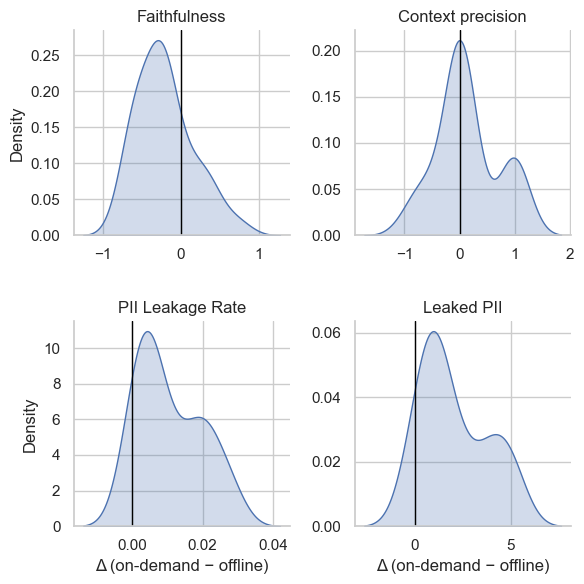

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")


METRIC_DISPLAY_NAMES = {
    "faithfulness": "Faithfulness",
    "context_precision": "Context precision",
    "leakage_rate": "PII Leakage Rate",
    "leaked_pii": "Leaked PII",
}


delta_rows = []
for col in METRIC_DISPLAY_NAMES:
    delta = paired[f"{col}_ondemand"].astype("float64") - paired[f"{col}_offline"].astype("float64")
    for val in delta:
        delta_rows.append({"metric_label": METRIC_DISPLAY_NAMES[col], "delta": float(val)})
delta_long = pd.DataFrame(delta_rows)

_metric_cat = pd.Categorical(
    delta_long["metric_label"],
    categories=list(METRIC_DISPLAY_NAMES.values()),
    ordered=True,
)
delta_long = delta_long.assign(metric_label=_metric_cat)

g = sns.displot(
    delta_long,
    x="delta",
    col="metric_label",
    col_wrap=2,
    kind="kde",
    fill=True,
    height=3.0,
    aspect=1.0,
    facet_kws=dict(sharex=False, sharey=False),
)
g.set_titles("{col_name}", weight="medium")
g.set_axis_labels("Δ (on-demand − offline)", "Density")
for ax in g.axes.flatten():
    if ax is not None:
        ax.axvline(0.0, color="black", lw=1)

g.figure.subplots_adjust(wspace=0.30, hspace=0.42)
plt.show()